YOU MUST STILL FILL IN THfE FOLLOWING VARIABLES:
VARIABLES START


varyingVariable,
hasBottail,
obtaining_motor_csv,
numberSims,
processes,
latitude,
longitude,
elevation,
atmosphere_type,
env_file,
fahrenheit_temp,
pressure,
wind_u,
wind_v,
date,
generatedFilesLocation,
dryMotorMass,
propellant_mass,
grainInnerRadius,
grainOuterRadius,
grainHeight,
the_nozzle_radius,
the_throat_radius,
the_nozzle_position,
grain_center_of_mass_position,
center_of_dry_mass_within_motor,
motor_thrust_file,
burn_time,
numGrains,
grainSeparation,
the_motor_position,
the_center_of_mass_without_motor,
rocket_center_of_dry_mass_position,
power_off_file,
power_on_file,
inclination,
heading,
rail_length,
using-airbrakes,
doing_monte_carlo,


VARIABLES END


Impulse is: 9680.79964519286
TOTAL SIMS IS: 30


'Completed 30 iterations successfully. Total CPU time: 0.046875 s. Total wall time: 11.633299589157104 s'

Number of simulations:  30
Out Of Rail Stability Margin -         Mean Value: 3.141 
Out Of Rail Stability Margin - Standard Deviation: 0.000 m
Arr: [np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.141227634469366), np.float64(3.

C:\Users\mahd\Documents\SimulationRocketPy\Helpers\FlightParams.py:507: RuntimeWarning: invalid value encountered in scalar divide
  changeInZ = (maximum - minimum) / numBins
C:\Users\mahd\Documents\SimulationRocketPy\Helpers\FlightParams.py:516: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.xlim(minimum, maximum)


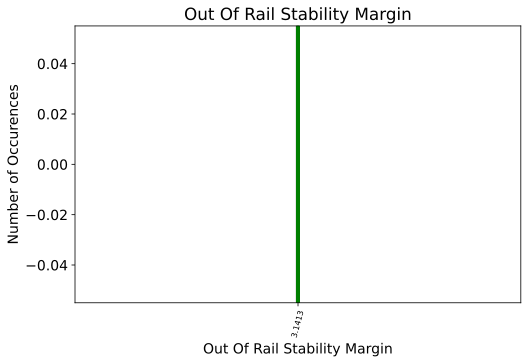

PROBABILITY THE Out Of Rail Stability Margin IS IN BETWEEN 1.5 AND 4 IS: 100.0%
There is a 90% chance that the mean of the Out Of Rail Stability Margin falls within THIS RANGE: 3.1412276344693644, 3.1412276344693653



Apogee Altitude -         Mean Value: 5792.355 
Apogee Altitude - Standard Deviation: 0.000 m
Arr: [np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434), np.float64(5792.354581654434),

C:\Users\mahd\Documents\SimulationRocketPy\Helpers\FlightParams.py:507: RuntimeWarning: invalid value encountered in scalar divide
  changeInZ = (maximum - minimum) / numBins
C:\Users\mahd\Documents\SimulationRocketPy\Helpers\FlightParams.py:516: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.xlim(minimum, maximum)


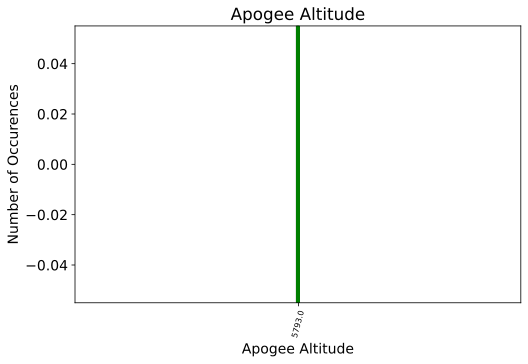

PROBABILITY THE Apogee Altitude IS IN BETWEEN 3017.52 AND 3078.48 IS: 0.0%
There is a 90% chance that the mean of the Apogee Altitude falls within THIS RANGE: 5792.35458165443, 5792.354581654432

We have the hypothesis that our mean is greater than or equal to 3048. With our critical percent, our critical value is -1.6448536269514729. Then, our test statistic is 5509084356528307.0
Since our test statistic is less extreme than our critical value, we can NOT reject the null hypothesis that the mean is 3048.




----------------------------------------------------------------------------------------------------






----------------------------------------------------------------------------------------------------





In [1]:
from time import process_time, time
import pandas as pd
from rocketpy import Environment, SolidMotor, Rocket, Flight
import concurrent.futures
from Helpers.ConcurrentFunctions import RunFlightWithMonteCarlo
from rocketpy.motors import motor
from IPython.display import display
from rocketpy.mathutils.function import Function
from rocketpy.environment import environment

import datetime

#Calculate and plot landing elipses
# Import libraries
from imageio import imread
from matplotlib.patches import Ellipse

from Helpers import FlightParams
from Helpers.Wind import MakeWind

%config InlineBackend.figure_formats = ['svg']
import matplotlib as mpl
import matplotlib.pyplot as plt

%matplotlib inline
mpl.rcParams["figure.figsize"] = [8, 5]
mpl.rcParams["figure.dpi"] = 120
mpl.rcParams["font.size"] = 14
mpl.rcParams["legend.fontsize"] = 14
mpl.rcParams["figure.titlesize"] = 14


import logging
import numpy as np

#sets up the ability to log inputs.
def setup_logging():
    class MyHandler(logging.FileHandler):
        def emit(self, record):
            super().emit(record)  # Call the superclass's emit method
            self.flush()  # Flush after each log message

    # Use your custom handler
    logger = logging.getLogger()
    logger.setLevel(logging.INFO)
    handler = MyHandler('app.log', 'a')
    formatter = logging.Formatter('%(asctime)s - %(levelname)s - %(message)s')
    handler.setFormatter(formatter)
    logger.addHandler(handler)

resultsFile = open(FlightParams.Parameters["generatedFilesLocation"] + "results.txt", "w")

# envParams["file"] = row[0].value

print("TOTAL SIMS IS: " + str(FlightParams.Parameters["numberSims"]))
resultsFile.write("TOTAL SIMS IS: " + str(FlightParams.Parameters["numberSims"]) + "\n\n\n")
    
setup_logging()
# env.all_info()
# Create data files for inputs, outputs and error logging
filename = "MonteCarlo1"
MonteCarloErrorFile = open("../Output/" + str(filename) + ".Errors.txt", "w")
MonteCarloInputFile = open("../Output/" + str(filename) + ".Input.txt", "w")
MonteCarloOutputFile = open("../Output/" + str(filename) + ".Output.txt", "w")

initial_wall_time = time()
initial_cpu_time = process_time()
# Iterate over flight settings
out = display("Starting", display_id=True)
number_of_simulations = FlightParams.Parameters["numberSims"]
totalProcesses = FlightParams.Parameters["processes"]
simsPerProcess = number_of_simulations / totalProcesses

# runFlightWithMonteCarlo(simsPerProcess, FlightParams.envParams, analysis_parameters, initial_cpu_time, False, theLaunchDate)

theDate = datetime.date.today()
theDate = [theDate.year, theDate.month, theDate.day, 12]

# start multiprocessing
if __name__ == "__main__":
    with concurrent.futures.ProcessPoolExecutor(max_workers=totalProcesses) as executor:
        results = [executor.submit(RunFlightWithMonteCarlo, simsPerProcess, initial_cpu_time, False, theDate) for _ in range(totalProcesses)] 
        for result in concurrent.futures.as_completed(results):
            MonteCarloInputFile.write(result.result()[0] + "\n")
            MonteCarloOutputFile.write(result.result()[1] + "\n")
            MonteCarloErrorFile.write(result.result()[2] + "\n")

## Print and save total time
final_string = f"Completed {number_of_simulations} iterations successfully. Total CPU time: {process_time() - initial_cpu_time} s. Total wall time: {time() - initial_wall_time} s"
resultsFile.write(f"Completed {number_of_simulations} iterations successfully. Total CPU time: {process_time() - initial_cpu_time} s. Total wall time: {time() - initial_wall_time} s\n")
out.update(final_string)
MonteCarloInputFile.write(final_string + "\n")
MonteCarloOutputFile.write(final_string + "\n")
MonteCarloErrorFile.write(final_string + "\n")

## Close files
MonteCarloInputFile.close()
MonteCarloOutputFile.close()
MonteCarloErrorFile.close()

# Initialize variable to store all results
dispersion_general_results = []

dispersion_results = {
    "out_of_rail_time": [],
    "out_of_rail_velocity": [],
    "apogee_time": [],
    "apogee_altitude": [],
    "apogee_x": [],
    "apogee_y": [],
    "impact_x": [],
    "impact_y": [],
    "initial_static_margin": [],
    "out_of_rail_static_margin": [],
    "out_of_rail_stability_margin": [],
    "max_velocity": [],
    "execution_time": [],
}

# Get all dispersion results
# Get file
dispersion_output_file = open("../Output/" + str(filename) + ".Output.txt", "r+")

# Read each line of the file and convert to dict
for line in dispersion_output_file:
    # Skip comments lines
    if line[0] != "{":
        continue
    # Eval results and store them
    flight_result = eval(line)
    dispersion_general_results.append(flight_result)
    for parameter_key, parameter_value in flight_result.items():
        dispersion_results[parameter_key].append(parameter_value)

# Close data file
dispersion_output_file.close()

# Print number of flights simulated
N = len(dispersion_general_results)
print("Number of simulations: ", N)
resultsFile.write("Number of simulations: " + str(N) + "\n")

# Retrieve dispersion data por apogee and impact XY position
apogee_x = np.array(dispersion_results["apogee_x"])
apogee_y = np.array(dispersion_results["apogee_y"])

FlightParams.createDistributionPlot(resultsFile, dispersion_results["out_of_rail_stability_margin"], "Out Of Rail Stability Margin", lowerProbBound = 1.5, upperProbBound = 4, maxDecimals = 4, percentConfidence = 90, hypothesis = None, unit = "none", makeGraph = True, filename = "Rail" + str(1))
print("\n\n")
resultsFile.write("\n\n")
FlightParams.createDistributionPlot(resultsFile, dispersion_results["apogee_altitude"], "Apogee Altitude", lowerProbBound = 9900 * 0.3048, upperProbBound = 10100 * 0.3048, maxDecimals = 0, percentConfidence = 90, hypothesis = 3048, unit = "meter", makeGraph = True, filename = "Apogee" + str(1))
print("\n\n\n----------------------------------------------------------------------------------------------------\n\n\n")
resultsFile.write("\n\n\n----------------------------------------------------------------------------------------------------\n\n\n")

print("\n\n\n----------------------------------------------------------------------------------------------------\n\n\n")
resultsFile.write("\n\n\n----------------------------------------------------------------------------------------------------\n\n\n")
        
resultsFile.close()